# MBAN 5110 - Assignment 1

This analysis uses bike purchase transactions to forecast total demand, estimate product-choice probabilities, and determine capacity, prices and quantities. Demand is measured in bikes and the logistic model predicts the product selected in a purchase transaction.

## Data preparation

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from statsmodels.stats.stattools import durbin_watson

import os
os.makedirs("outputs", exist_ok=True)


In [4]:
df_transactions = pd.read_csv("sales_transactions.csv")
print(df_transactions.head())


             Product  quantity  order_date delivery_date  \
0        Tough Track         1  2021-02-07    2021-02-20   
1  Ultimate Mountain         2  2021-02-08    2021-02-19   
2  Ultimate Mountain         1  2021-02-11    2021-02-20   
3  Ultimate Mountain         1  2021-02-15    2021-02-23   
4   Comfort Mountain         1  2021-02-20    2021-02-28   

   Price_Comfort_Mountain  Price_Tough_Track  Price_Ultimate_Mountain  
0                    4939               1680                      480  
1                    4870               2102                      649  
2                    4564               2029                      525  
3                    4075               2263                      240  
4                    3360               1800                      649  


In [5]:
print("Rows:", len(df_transactions))
print("Bikes:", df_transactions["quantity"].sum())
print(df_transactions.isna().sum())
print("Exact duplicates:", df_transactions.duplicated().sum())
print(df_transactions.groupby("Product")["quantity"].sum())


Rows: 1682
Bikes: 2051
Product                    0
quantity                   0
order_date                 0
delivery_date              0
Price_Comfort_Mountain     0
Price_Tough_Track          0
Price_Ultimate_Mountain    0
dtype: int64
Exact duplicates: 0
Product
Comfort Mountain     662
Tough Track          707
Ultimate Mountain    682
Name: quantity, dtype: int64


The dataset contains 1,682 transactions and 2,051 bikes, with no missing values or exact duplicate rows. Product totals are 662 Comfort Mountain, 707 Tough Track
and 682 Ultimate Mountain bikes. Delivery dates define selling-period demand. Order dates determine which bookings are known when a decision is made.

## Question 1: Two-week OLS forecasts

Deliveries are grouped into consecutive 14-day intervals beginning on Monday, February 15, 2021. The first and last intervals are excluded because the dataset
does not document complete coverage at its boundaries. Interior periods without transactions are treated as zero observed sales.

In [6]:
df_tmp = df_transactions.copy()
df_tmp["order_date"] = pd.to_datetime(df_tmp["order_date"])
df_tmp["delivery_date"] = pd.to_datetime(df_tmp["delivery_date"])

print(df_tmp[["order_date", "delivery_date"]].agg(["min", "max"]))
print("Orders after delivery:",
      (df_tmp["order_date"] > df_tmp["delivery_date"]).sum())


    order_date delivery_date
min 2021-02-07    2021-02-19
max 2026-01-31    2026-02-08
Orders after delivery: 0


In [7]:
anchor = pd.Timestamp("2021-02-15")
days_since_anchor = (df_tmp["delivery_date"] - anchor).dt.days
period_number = days_since_anchor // 14

df_tmp["period_start"] = anchor + pd.to_timedelta(
    period_number * 14, unit="D"
)
print(df_tmp[["delivery_date", "period_start"]].head())


  delivery_date period_start
0    2021-02-20   2021-02-15
1    2021-02-19   2021-02-15
2    2021-02-20   2021-02-15
3    2021-02-23   2021-02-15
4    2021-02-28   2021-02-15


### Forecast timing and advance orders

All lead times are measured before the **start** of the target selling period. A horizon of one means 14 days before selling starts, and a horizon of four means
56 days before selling starts. I use four two-week periods to approximate two months because the assignment uses two-week aggregation and forecast horizons 1 to 4. This keeps the reservation on the same forecasting grid. It is a 56-day convention, not an exact calendar-month offset. Using two calendar months would require different decision dates and a new check of which completed periods and bookings were available at each date. 
| Horizon | Decision date relative to selling start | Latest completed demand |
|---|---|---|
| 1 | 14 days earlier | Two periods earlier |
| 2 | 28 days earlier | Three periods earlier |
| 3 | 42 days earlier | Four periods earlier |
| 4 | 56 days earlier | Five periods earlier |

Only orders placed strictly before the relevant cutoff count as advance orders.

In [8]:
is_advance1 = df_tmp["order_date"] < (
    df_tmp["period_start"] - pd.to_timedelta(14, unit="D")
)
is_advance2 = df_tmp["order_date"] < (
    df_tmp["period_start"] - pd.to_timedelta(28, unit="D")
)
df_tmp["advance1"] = df_tmp["quantity"].where(is_advance1, 0)
df_tmp["advance2"] = df_tmp["quantity"].where(is_advance2, 0)


In [9]:
is_advance3 = df_tmp["order_date"] < (
    df_tmp["period_start"] - pd.to_timedelta(42, unit="D")
)
is_advance4 = df_tmp["order_date"] < (
    df_tmp["period_start"] - pd.to_timedelta(56, unit="D")
)
df_tmp["advance3"] = df_tmp["quantity"].where(is_advance3, 0)
df_tmp["advance4"] = df_tmp["quantity"].where(is_advance4, 0)


### Aggregate quantities across the three products

In [10]:
columns_to_sum = ["quantity", "advance1", "advance2", "advance3", "advance4"]

df_two_week_demand = df_tmp.groupby("period_start")[columns_to_sum].sum()
df_two_week_demand = df_two_week_demand.rename(
    columns={"quantity": "total_demand"}
)
print(df_two_week_demand.head())


              total_demand  advance1  advance2  advance3  advance4
period_start                                                      
2021-02-15               6         0         0         0         0
2021-03-01               4         0         0         0         0
2021-03-15               4         0         0         0         0
2021-03-29              12         0         0         0         0
2021-04-12              10         0         0         0         0


In [11]:
all_periods = pd.date_range(
    df_tmp["period_start"].min(),
    df_tmp["period_start"].max(),
    freq="14D"
)
df_two_week_demand = df_two_week_demand.reindex(all_periods, fill_value=0)
df_two_week_demand.index.name = "period_start"
df_two_week_demand = df_two_week_demand.reset_index()

print("Grouped bikes:", df_two_week_demand["total_demand"].sum())
df_two_week_demand.to_csv("outputs/all_two_week_totals.csv", index=False)


Grouped bikes: 2051


In [12]:
df_two_week_demand = df_two_week_demand.iloc[1:-1].copy()
df_two_week_demand = df_two_week_demand.reset_index(drop=True)
df_two_week_demand["period_end"] = (
    df_two_week_demand["period_start"] + pd.to_timedelta(14, unit="D")
)

print("Retained periods:", len(df_two_week_demand))
print(df_two_week_demand.head())


Retained periods: 128
  period_start  total_demand  advance1  advance2  advance3  advance4  \
0   2021-03-01             4         0         0         0         0   
1   2021-03-15             4         0         0         0         0   
2   2021-03-29            12         0         0         0         0   
3   2021-04-12            10         0         0         0         0   
4   2021-04-26            13         0         0         0         0   

  period_end  
0 2021-03-15  
1 2021-03-29  
2 2021-04-12  
3 2021-04-26  
4 2021-05-10  


### Historical demand inputs

The input at horizon h uses `shift(h + 1)`. At 14 days before the target starts, the immediately preceding fortnight is only starting, so its full demand is unavailable. The latest completed period is two rows earlier. The same reasoning applies to the longer horizons.

After excluding the two boundary periods, 128 periods remain. A common sample of 123 observations is used for the four OLS fits so their fit statistics are comparable.

In [13]:
df_two_week_demand["demand_at_h1"] = df_two_week_demand["total_demand"].shift(2)
df_two_week_demand["demand_at_h2"] = df_two_week_demand["total_demand"].shift(3)
df_two_week_demand["demand_at_h3"] = df_two_week_demand["total_demand"].shift(4)
df_two_week_demand["demand_at_h4"] = df_two_week_demand["total_demand"].shift(5)
print(df_two_week_demand.head(7))


  period_start  total_demand  advance1  advance2  advance3  advance4  \
0   2021-03-01             4         0         0         0         0   
1   2021-03-15             4         0         0         0         0   
2   2021-03-29            12         0         0         0         0   
3   2021-04-12            10         0         0         0         0   
4   2021-04-26            13         0         0         0         0   
5   2021-05-10            12         0         0         0         0   
6   2021-05-24            15         0         0         0         0   

  period_end  demand_at_h1  demand_at_h2  demand_at_h3  demand_at_h4  
0 2021-03-15           NaN           NaN           NaN           NaN  
1 2021-03-29           NaN           NaN           NaN           NaN  
2 2021-04-12           4.0           NaN           NaN           NaN  
3 2021-04-26           4.0           4.0           NaN           NaN  
4 2021-05-10          12.0           4.0           4.0           NaN

In [14]:
lag_columns = ["demand_at_h1", "demand_at_h2", "demand_at_h3", "demand_at_h4"]
df_q1 = df_two_week_demand.dropna(subset=lag_columns).copy()
print("Q1 rows:", len(df_q1))
print(df_q1[["advance1", "advance2", "advance3", "advance4"]].sum())


Q1 rows: 123
advance1    2
advance2    0
advance3    0
advance4    0
dtype: int64


### Horizon 1

Total demand is regressed on the latest completed demand and known advance orders. Advance-order columns at horizons 2–4 are identically zero and are therefore excluded from those models.

In [15]:
Y = df_q1["total_demand"]
X = df_q1[["demand_at_h1", "advance1"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results1 = model.fit()
print(results1.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     95.93
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.30e-25
Time:                        10:50:37   Log-Likelihood:                -427.97
No. Observations:                 123   AIC:                             861.9
Df Residuals:                     120   BIC:                             870.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.4184      1.167      2.930   

### Horizon 2

In [16]:
Y = df_q1["total_demand"]
X = df_q1[["demand_at_h2"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results2 = model.fit()
print(results2.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.425
Model:                            OLS   Adj. R-squared:                  0.421
Method:                 Least Squares   F-statistic:                     89.54
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           3.07e-16
Time:                        10:50:37   Log-Likelihood:                -452.64
No. Observations:                 123   AIC:                             909.3
Df Residuals:                     121   BIC:                             914.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            5.5377      1.420      3.899   

### Horizon 3

In [17]:
Y = df_q1["total_demand"]
X = df_q1[["demand_at_h3"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results3 = model.fit()
print(results3.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.257
Method:                 Least Squares   F-statistic:                     43.09
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.37e-09
Time:                        10:50:37   Log-Likelihood:                -467.97
No. Observations:                 123   AIC:                             939.9
Df Residuals:                     121   BIC:                             945.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            7.8191      1.608      4.863   

### Horizon 4

In [18]:
Y = df_q1["total_demand"]
X = df_q1[["demand_at_h4"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results4 = model.fit()
print(results4.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.127
Model:                            OLS   Adj. R-squared:                  0.120
Method:                 Least Squares   F-statistic:                     17.65
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.09e-05
Time:                        10:50:37   Log-Likelihood:                -478.32
No. Observations:                 123   AIC:                             960.6
Df Residuals:                     121   BIC:                             966.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           10.3815      1.743      5.957   

### Comparison of the four fitted models

In [19]:
q1_summary = pd.DataFrame({
    "Horizon": [1, 2, 3, 4],
    "R_squared": [results1.rsquared, results2.rsquared,
                  results3.rsquared, results4.rsquared],
    "RMSE_in_sample": [np.sqrt(np.mean(results1.resid**2)),
                       np.sqrt(np.mean(results2.resid**2)),
                       np.sqrt(np.mean(results3.resid**2)),
                       np.sqrt(np.mean(results4.resid**2))]
})
print(q1_summary)
q1_summary.to_csv("outputs/q1_summary.csv", index=False)


   Horizon  R_squared  RMSE_in_sample
0        1   0.615205        7.849535
1        2   0.425279        9.593077
2        3   0.262612       10.866198
3        4   0.127330       11.821005


The horizon-1 model explains about 62% of the variation in the fitted sample, compared with about 13% for horizon 4. Its in-sample RMSE is 7.85 bikes, compared with 11.82 bikes at horizon 4. More recent sales information gives a stronger fit. These are fitting results, not held-out forecast errors. The negative advance-order coefficient at horizon 1 is statistically weak and does not show that advance orders reduce demand.

## Question 2: Product-choice probabilities

The target is the purchased model, and the inputs are the prices of all three models, in Comfort Mountain, Tough Track and Ultimate Mountain order. The model uses one observation per transaction. Prices remain in dollars. A larger iteration limit and tighter tolerance are used to obtain a converged fit.

In [20]:
price_columns = ["Price_Comfort_Mountain", "Price_Tough_Track",
                 "Price_Ultimate_Mountain"]
y = np.array(df_transactions["Product"])
X = np.array(df_transactions[price_columns])
print(X.shape)


(1682, 3)


In [21]:
model_classification = LogisticRegression(
    random_state=0, max_iter=20000, tol=1e-8
).fit(X, y)

print(model_classification.classes_)
print("Iterations used:", model_classification.n_iter_)


['Comfort Mountain' 'Tough Track' 'Ultimate Mountain']
Iterations used: [205]


### Choice probabilities at $4,200, $1,950 and $500

In [22]:
prices = np.array([[4200, 1950, 500]])
probabilities = model_classification.predict_proba(prices)[0]

q2_probabilities = pd.DataFrame({
    "Product": model_classification.classes_,
    "Price": [4200, 1950, 500],
    "Probability": probabilities,
    "Percent": probabilities * 100
})
print(q2_probabilities)
print("Probability sum:", probabilities.sum())
q2_probabilities.to_csv("outputs/q2_probabilities.csv", index=False)


             Product  Price  Probability    Percent
0   Comfort Mountain   4200     0.181976  18.197606
1        Tough Track   1950     0.298945  29.894513
2  Ultimate Mountain    500     0.519079  51.907881
Probability sum: 1.0


At the specified prices, the estimated probabilities are **18.20% Comfort Mountain, 29.89% Tough Track and 51.91% Ultimate Mountain**. Ultimate Mountain is the most likely selection. The probabilities sum to one because the model is conditional on selecting one of the three bikes but they do not describe the probability that an arbitrary visitor buys a bike.

## Question 3: Capacity, prices and quantities

### Forecast-based capacity reservation policy

Reserved capacity equals the **horizon-4 point forecast**. Negative predictions are clipped at zero, and the result is rounded to the nearest whole bike, with half units rounded upward. The raw forecast and the nonnegative point estimate are retained separately. This is a forecast-based reservation policy. Prices and quantities are optimized
within that fixed reservation; capacity itself is not selected by an economic optimization model.

Two months is approximated by four two-week periods to match the forecasting grid. Capacity is reserved 56 days before the selling period starts. Prices and quantities are set 14 days before it starts. The two decisions are six weeks apart. For the period starting January 27, 2025, these dates are December 2, 2024 and January 13, 2025.

In [23]:
df_two_week_demand["capacity_date"] = df_two_week_demand["period_start"] - pd.to_timedelta(56, unit="D")
df_two_week_demand["ordering_date"] = df_two_week_demand["period_start"] - pd.to_timedelta(14, unit="D")
print(df_two_week_demand[["period_start", "capacity_date", "ordering_date"]].tail())


    period_start capacity_date ordering_date
123   2025-11-17    2025-09-22    2025-11-03
124   2025-12-01    2025-10-06    2025-11-17
125   2025-12-15    2025-10-20    2025-12-01
126   2025-12-29    2025-11-03    2025-12-15
127   2026-01-12    2025-11-17    2025-12-29


### Chronological training and test sets

The last 20% of retained periods form the test set: 26 periods from January 27, 2025 through January 25, 2026. The end boundary is January 26, 2026, exclusive.
Training ends at the first capacity-decision date, December 2, 2024. Only completed training-period outcomes are included in estimation. The capacity regression uses 93 observations and the later regression uses 96. Model coefficients stay fixed during testing. Earlier test-period sales become available as lagged inputs only after those periods have ended.

In [24]:
number_test = int(np.ceil(0.20 * len(df_two_week_demand)))
df_test = df_two_week_demand.tail(number_test).copy()
training_cutoff = df_test["capacity_date"].iloc[0]
df_train_capacity = df_two_week_demand[
    df_two_week_demand["period_end"] <= training_cutoff
].dropna(subset=["demand_at_h4"])
df_train_ordering = df_two_week_demand[
    df_two_week_demand["period_end"] <= training_cutoff
].dropna(subset=["demand_at_h1"])
print(training_cutoff, len(df_test))
print("Training rows:", len(df_train_capacity), len(df_train_ordering))


2024-12-02 00:00:00 26
Training rows: 93 96


### Training-only horizon-4 OLS model

In [25]:
Y = df_train_capacity["total_demand"]
X = df_train_capacity[["demand_at_h4"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results_capacity = model.fit()
print(results_capacity.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     10.14
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00198
Time:                        10:50:37   Log-Likelihood:                -348.46
No. Observations:                  93   AIC:                             700.9
Df Residuals:                      91   BIC:                             706.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            9.7132      1.776      5.469   

### Training-only horizon-1 OLS model

In [26]:
Y = df_train_ordering["total_demand"]
X = df_train_ordering[["demand_at_h1", "advance1"]]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results_ordering = model.fit()
print(results_ordering.summary())


                            OLS Regression Results                            
Dep. Variable:           total_demand   R-squared:                       0.569
Model:                            OLS   Adj. R-squared:                  0.559
Method:                 Least Squares   F-statistic:                     61.33
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.03e-17
Time:                        10:50:37   Log-Likelihood:                -322.98
No. Observations:                  96   AIC:                             652.0
Df Residuals:                      93   BIC:                             659.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.5506      1.201      2.957   

### Residual diagnostics

In [27]:
ols_models = [results1, results2, results3, results4,
              results_capacity, results_ordering]
model_names = ["Q1 horizon 1", "Q1 horizon 2", "Q1 horizon 3", "Q1 horizon 4",
               "Q3 horizon 4", "Q3 horizon 1"]
dw_values = []
for results in ols_models:
    dw_values.append(durbin_watson(results.resid))

residual_diagnostics = pd.DataFrame({
    "Model": model_names,
    "Durbin_Watson": dw_values
})
print(residual_diagnostics.round(3))
residual_diagnostics.to_csv("outputs/ols_residual_diagnostics.csv", index=False)

          Model  Durbin_Watson
0  Q1 horizon 1          1.119
1  Q1 horizon 2          0.896
2  Q1 horizon 3          0.604
3  Q1 horizon 4          0.497
4  Q3 horizon 4          0.555
5  Q3 horizon 1          1.219


The Durbin–Watson values are well below 2, suggesting that errors in nearby periods tend to move in the same direction. A run of under-forecasts can therefore leave several consecutive periods with insufficient reserved capacity. The models do not capture all of the pattern over time. Conventional OLS standard errors and p-values should be interpreted cautiously because independent errors are doubtful. The chronological test results assess forecast accuracy, but they do not remove this limitation. The training-only advance-order coefficient is also statistically weak and should not be interpreted as a causal effect.

### Training-only product-choice model

Product choices are observed at the order date. The choice model uses 1,128 transactions placed before the training cutoff. Its test set contains 526 transactions placed during the test calendar window. This evaluates order-date choices, whereas the OLS evaluation uses delivery-period totals.

In [28]:
df_choice_train = df_tmp[df_tmp["order_date"] < training_cutoff].copy()
test_start = df_test["period_start"].iloc[0]
test_end = df_test["period_end"].iloc[-1]
df_choice_test = df_tmp[
    (df_tmp["order_date"] >= test_start) &
    (df_tmp["order_date"] < test_end)
].copy()
print("Choice training/test rows:", len(df_choice_train), len(df_choice_test))


Choice training/test rows: 1128 526


In [29]:
y = np.array(df_choice_train["Product"])
X = np.array(df_choice_train[price_columns])
model_classification_train = LogisticRegression(
    random_state=0, max_iter=20000, tol=1e-8
).fit(X, y)
product_names = model_classification_train.classes_
print(product_names)


['Comfort Mountain' 'Tough Track' 'Ultimate Mountain']


### Held-out product-choice assessment

In [30]:
X_test = np.array(df_choice_test[price_columns])
y_test = np.array(df_choice_test["Product"])
predictions = model_classification_train.predict(X_test)
test_f1 = f1_score(y_test, predictions, average="weighted")
print("Test weighted F1:", test_f1)
pd.DataFrame({"Test_rows": [len(y_test)], "Weighted_F1": [test_f1]}).to_csv(
    "outputs/q3_choice_score.csv", index=False
)


Test weighted F1: 0.8801206359765542


The held-out weighted F1 is **0.8801**. This measures prediction of purchased product labels. It cannot validate the separate assumption about whether potential customers buy at all. 

### Product-level classification results

In [31]:
# Rows show actual products and columns show predicted products
choice_matrix = pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=product_names),
    index=product_names, columns=product_names
)
choice_matrix.index.name = "Actual product"
choice_matrix.columns.name = "Predicted product"
print(choice_matrix)
choice_matrix.to_csv("outputs/q3_choice_confusion_matrix.csv")

Predicted product  Comfort Mountain  Tough Track  Ultimate Mountain
Actual product                                                     
Comfort Mountain                161            8                  9
Tough Track                       8          139                 18
Ultimate Mountain                10           10                163


In [32]:
choice_report = classification_report(
    y_test, predictions, labels=product_names, output_dict=True, zero_division=0
)
product_scores = pd.DataFrame(choice_report).T.loc[
    product_names, ["precision", "recall", "f1-score", "support"]
]
print(product_scores.round(3))
product_scores.to_csv("outputs/q3_choice_product_scores.csv")

                   precision  recall  f1-score  support
Comfort Mountain       0.899   0.904     0.902    178.0
Tough Track            0.885   0.842     0.863    165.0
Ultimate Mountain      0.858   0.891     0.874    183.0


Precision measures how often a predicted product is correct. Recall measures how many actual purchases of that product are identified. F1 balances precision
and recall, and support is the number of test transactions for each product. The diagonal of the confusion matrix contains correct predictions; other entries
show which products are confused. These results concern product selection among buyers, not visitor conversion or the accuracy of recommended prices.

The results are Comfort Mountain: precision 0.899, recall 0.904 and F1 0.902; Tough Track: precision 0.885, recall 0.842 and F1 0.863; Ultimate Mountain: precision 0.858, recall 0.891 and F1 0.874. Comfort Mountain has the highest F1. The largest confusion is 18 actual Tough Track purchases predicted as Ultimate Mountain. The weighted F1 combines the products according to their test transaction counts, so it does not describe every product equally well.

### Effect of a Comfort Mountain discount

In [33]:
# Reduce only the Comfort Mountain price by 10%
avg_prices = df_choice_train[price_columns].mean()
base = model_classification_train.predict_proba(
    np.array(avg_prices).reshape(1, 3)
).ravel()

discount = np.array([10, 0, 0])
price = avg_prices * (100 - discount) / 100
actual = model_classification_train.predict_proba(
    np.array(price).reshape(1, 3)
).ravel()

price_effect = pd.DataFrame({
    "Product": product_names,
    "Original_price": np.array(avg_prices),
    "Discounted_price": np.array(price),
    "Original_share_percent": base * 100,
    "Discounted_share_percent": actual * 100,
    "Change_percentage_points": (actual - base) * 100
})
print(price_effect.round(2))
price_effect.to_csv("outputs/q3_choice_price_effect.csv", index=False)

             Product  Original_price  Discounted_price  \
0   Comfort Mountain         4220.92           3798.83   
1        Tough Track         1912.61           1912.61   
2  Ultimate Mountain          523.34            523.34   

   Original_share_percent  Discounted_share_percent  Change_percentage_points  
0                   18.75                     78.26                     59.51  
1                   44.32                     13.27                    -31.05  
2                   36.93                      8.47                    -28.46  


The comparison holds Tough Track and Ultimate Mountain prices fixed at their training averages. It shows how the fitted product shares respond to a change in
one price. Each row's change is measured in percentage points, and the changes sum to zero because the three conditional shares still sum to 100%. Historical
price associations do not prove the causal effect of offering a discount. This calculation does not include the separate no-purchase assumption.

Reducing Comfort Mountain's price from $4,220.92 to $3,798.83 changes its fitted share from 18.75% to 78.26%, a change of 59.51 percentage points. The other two shares adjust while their prices stay fixed. 

### Forecasts available at the two decision dates

In [34]:
X_capacity = sm.add_constant(df_test[["demand_at_h4"]], has_constant="add")
X_ordering = sm.add_constant(df_test[["demand_at_h1", "advance1"]], has_constant="add")
df_test["forecast_h4"] = results_capacity.predict(X_capacity)
df_test["forecast_h1"] = results_ordering.predict(X_ordering)
print(df_test[["period_start", "forecast_h4", "forecast_h1"]].head())


    period_start  forecast_h4  forecast_h1
102   2025-01-27    11.610524    13.351360
103   2025-02-10    11.294308    10.335750
104   2025-02-24    11.926739     8.074042
105   2025-03-10    13.824034     9.581847
106   2025-03-24    12.559171    18.628679


### Reserved capacity from the early point estimate

In [35]:
df_test["capacity_point"] = np.maximum(df_test["forecast_h4"], 0)
df_test["capacity"] = np.floor(df_test["capacity_point"] + 0.5).astype(int)
print(df_test[["period_start", "capacity_point", "capacity"]].head())


    period_start  capacity_point  capacity
102   2025-01-27       11.610524        12
103   2025-02-10       11.294308        11
104   2025-02-24       11.926739        12
105   2025-03-10       13.824034        14
106   2025-03-24       12.559171        13


### Known commitments

Orders already placed before the later decision are treated as binding commitments. Their products and recorded contract prices remain fixed. Recommended prices apply only to new orders. Booked quantities are subtracted from both capacity and forecast demand to avoid double counting. If commitments exceed reserved capacity, preserving every commitment is infeasible. The pricing function reports that conflict rather than expanding capacity silently.

In [36]:
booking_rows = []
for start in df_test["period_start"]:
    cutoff = start - pd.to_timedelta(14, unit="D")
    known = df_tmp[(df_tmp["period_start"] == start) & (df_tmp["order_date"] < cutoff)]
    quantities = known.groupby("Product")["quantity"].sum().reindex(product_names, fill_value=0)
    revenue = 0.0
    for j in range(3):
        selected = known[known["Product"] == product_names[j]]
        revenue = revenue + (selected["quantity"] * selected[price_columns[j]]).sum()
    booking_rows.append([quantities.iloc[0], quantities.iloc[1], quantities.iloc[2], revenue])
df_bookings = pd.DataFrame(booking_rows, columns=[
    "booked_comfort", "booked_tough", "booked_ultimate", "booked_revenue"
])
print(df_bookings.head())


   booked_comfort  booked_tough  booked_ultimate  booked_revenue
0               0             0                0             0.0
1               0             0                0             0.0
2               0             0                0             0.0
3               0             0                0             0.0
4               0             0                0             0.0


In [37]:
df_test = df_test.reset_index(drop=True)
df_test = pd.concat([df_test, df_bookings], axis=1)
booked_columns = ["booked_comfort", "booked_tough", "booked_ultimate"]
df_test["booked_total"] = df_test[booked_columns].sum(axis=1)
df_test["remaining_forecast"] = np.maximum(df_test["forecast_h1"] - df_test["booked_total"], 0)
df_test["remaining_capacity"] = df_test["capacity"] - df_test["booked_total"]
print("Commitment conflicts:", (df_test["remaining_capacity"] < 0).sum())
print("Known booked bikes:", df_test["booked_total"].sum())


Commitment conflicts: 0
Known booked bikes: 0


There are **zero recorded advance bookings** for the 26 test periods before their two-week decision cutoffs, and no commitment-capacity conflicts. Under this timing convention, the newer completed sales periods drive the test-period forecast updates. The commitment calculation preserves existing orders if they are present; their effect is zero for these particular test observations.

### Revenue objective and candidate prices

Because purchase costs and capacity fees are not supplied, the later decision maximizes **modeled revenue**, not profit. Each product has five candidate prices:
its training-sample 10th, 30th, 50th, 70th and 90th percentiles. All 125 combinations are considered. This bounds each price within the training data, although some
combinations may not have been jointly observed. The reference basket uses training median prices. Average units per purchased model are also calculated from training data to translate transaction-choice probabilities into bike quantities. Order sizes are assumed stable.

In [38]:
reference_prices = np.array(df_choice_train[price_columns].median())
reference_shares = model_classification_train.predict_proba(reference_prices.reshape(1, 3))[0]
average_units = np.array(df_choice_train.groupby("Product")["quantity"].mean().reindex(product_names))
reference_order_size = np.sum(reference_shares * average_units)
price_options = []
for comfort in df_choice_train[price_columns[0]].quantile([0.1, 0.3, 0.5, 0.7, 0.9]):
    for tough in df_choice_train[price_columns[1]].quantile([0.1, 0.3, 0.5, 0.7, 0.9]):
        for ultimate in df_choice_train[price_columns[2]].quantile([0.1, 0.3, 0.5, 0.7, 0.9]):
            price_options.append([comfort, tough, ultimate])
price_options = np.round(np.array(price_options), 2)
probability_options = model_classification_train.predict_proba(price_options)
print(reference_prices, average_units, len(price_options))


[4254. 1982.  560.] [1.21875    1.24111675 1.19895288] 125


### No-purchase behavior

Purchase transactions do not identify how many potential customers leave without buying. A separate participation scenario addresses this limitation. No artificial no-purchase observations are added to the training data. Let $r_0$ be purchase probability at the reference basket and $I(p)$ be a price index, weighted by the product-choice shares at reference prices. The assumed purchase odds are

$$O(p)=\frac{r_0}{1-r_0}I(p)^{-s}, \qquad r(p)=\frac{O(p)}{1+O(p)}.$$

The central scenario uses $r_0=0.50$ and $s=2$. The symmetric reference rate is an illustrative baseline, not an estimate for this store. The response of 2 means
a 1% increase in the basket price lowers purchase odds by approximately 2%. Higher overall prices are assumed to reduce participation; the magnitude is unknown. Sensitivity analysis uses reference conversion rates of 25%, 50% and 75%, and response parameters of 1, 2 and 3. These are stress scenarios, not confidence intervals or empirically established bounds.

In [39]:
def purchase_rate(prices, base_conversion, sensitivity):
    price_index = np.sum(reference_shares * prices / reference_prices)
    reference_odds = base_conversion / (1 - base_conversion)
    odds = reference_odds * price_index ** (-sensitivity)
    return odds / (1 + odds)

base_conversion = 0.50
price_sensitivity = 2.0
print("At reference prices:", purchase_rate(reference_prices, base_conversion, price_sensitivity))
print("All prices 10% higher:", purchase_rate(reference_prices * 1.10, base_conversion, price_sensitivity))


At reference prices: 0.5
All prices 10% higher: 0.4524886877828054


### Unconditional choice probabilities

Multiplying conditional product shares by the assumed purchase probability gives the three unconditional product probabilities. The fourth probability is no
purchase. At reference prices, the purchase rate is 50%; when all prices rise by 10%, the central scenario reduces it to approximately 45.25%.

In [40]:
example_prices = reference_prices * 1.10
buy_probability = purchase_rate(example_prices, base_conversion, price_sensitivity)
conditional_shares = model_classification_train.predict_proba(example_prices.reshape(1, 3))[0]
four_probabilities = np.append(buy_probability * conditional_shares, 1 - buy_probability)
print(pd.DataFrame({"Choice": list(product_names) + ["No purchase"],
                    "Probability": four_probabilities}))
print("Sum:", four_probabilities.sum())


              Choice  Probability
0   Comfort Mountain     0.094243
1        Tough Track     0.031659
2  Ultimate Mountain     0.326587
3        No purchase     0.547511
Sum: 1.0


### Allocate remaining capacity

For fixed prices, additional whole bikes are assigned to the product with the largest incremental modeled revenue. Sales cannot exceed either the order quantity or the point-demand estimate. Each product's marginal revenue declines as its forecast demand is filled, making this allocation optimal for the stated fixed-price, separable revenue objective.

In [41]:
def choose_quantities(demand, prices, capacity):
    quantities = np.array([0, 0, 0])
    while quantities.sum() < capacity:
        extra_sales = np.minimum(1, np.maximum(demand - quantities, 0))
        extra_revenue = prices * extra_sales
        best_product = np.argmax(extra_revenue)
        if extra_revenue[best_product] <= 0:
            break
        quantities[best_product] = quantities[best_product] + 1
    return quantities


A small numerical check uses demand of 1.5, 1 and 1 bikes, prices of $10, $8 and $5, and two available slots. The optimal allocation is one Comfort and one Tough bike, producing modeled revenue of $18.

In [42]:
example_quantities = choose_quantities(
    np.array([1.5, 1.0, 1.0]), np.array([10.0, 8.0, 5.0]), 2
)
print(example_quantities)


[1 1 0]


### Search the price grid

The OLS forecast already represents purchased bikes rather than visitors. The remaining forecast is interpreted as purchases at the reference price basket.
Potential customers are calibrated as 

$$N=\frac{\text{remaining forecast}}{r_0\times\text{reference expected order size}}.$$

At candidate prices, demand for model $j$ is $N r(p) P(j\mid\text{purchase},p)$ times its training average order size. At reference prices, this calculation reproduces the remaining bike forecast. It therefore avoids discounting an already observed purchase forecast a second time for no-purchase behavior. 

For each price combination, the allocation function maximizes new-order revenue within remaining capacity. The best combination is retained. Existing contract revenue is fixed and added separately. Equal-revenue ties retain the first grid candidate. Prices have no operational effect when no new orders can be served.

In [43]:
def find_best_plan(remaining_demand, remaining_capacity, conversion, sensitivity):
    if remaining_capacity < 0:
        raise ValueError("Booked orders exceed reserved capacity: report this conflict.")
    potential_customers = remaining_demand / (conversion * reference_order_size)
    best_revenue = -np.inf
    for i in range(len(price_options)):
        prices = price_options[i]
        buy = purchase_rate(prices, conversion, sensitivity)
        demand = potential_customers * buy * probability_options[i] * average_units
        quantities = choose_quantities(demand, prices, remaining_capacity)
        revenue = np.sum(prices * np.minimum(quantities, demand))
        if revenue > best_revenue:
            best_revenue = revenue
            best_prices = prices.copy()
            best_quantities = quantities.copy()
    return best_prices, best_quantities, best_revenue


### Assumptions behind the recommendations

| Category | Item | Basis and role |
|---|---|---|
| Estimated from training data | OLS coefficients and logistic coefficients | Predict purchased bikes and product choice among buyers. |
| Calculated from training data | Median prices, five candidate prices per product and average order sizes | Define the reference basket, price grid and conversion from transactions to bikes. |
| Reservation policy | Nonnegative, rounded horizon-4 forecast | Follows the instructor's clarification and stays fixed at the later decision. |
| Timing assumption | Four two-week periods represent two months | Capacity is reserved 56 days before selling, on the same forecasting grid. |
| Optimization assumption | Maximize modeled revenue within the 125 price combinations | Costs are unavailable, so profit is not calculated. |
| No-purchase assumptions | Reference purchase rate 50% and price response 2 | Illustrative central scenario; neither parameter is estimated from purchase transactions. |
| Demand assumptions | Reference-price calibration and stable average order sizes | The forecast represents purchases at median prices; potential traffic is fixed within each scenario. |
| Decisions that can change across scenarios | Product prices and quantities | Sensitivity uses purchase rates of 25%, 50% and 75% and responses of 1, 2 and 3. Capacity stays unchanged. |

The following prices and quantities are **conditional scenario recommendations**.
They maximize the stated revenue calculation on the candidate grid under the
central assumptions. They are not uniquely established profit-maximizing decisions.

### Later price and quantity decisions for every test period

In [44]:
plans = []
for i in range(len(df_test)):
    row = df_test.iloc[i]
    prices, extra_quantities, revenue = find_best_plan(
        row["remaining_forecast"], int(row["remaining_capacity"]),
        base_conversion, price_sensitivity
    )
    booked = np.array(row[booked_columns], dtype=int)
    quantities = booked + extra_quantities
    plans.append(list(prices) + list(quantities) + [revenue + row["booked_revenue"]])
df_plans = pd.DataFrame(plans, columns=[
    "price_comfort", "price_tough", "price_ultimate",
    "quantity_comfort", "quantity_tough", "quantity_ultimate", "modeled_revenue"
])


### Complete test-period decision table

In [45]:
df_results = df_test[["period_start", "capacity_date", "ordering_date",
    "forecast_h4", "forecast_h1", "capacity_point", "capacity", "total_demand",
    "booked_comfort", "booked_tough", "booked_ultimate", "booked_total", "booked_revenue"]].copy()
df_results = pd.concat([df_results, df_plans], axis=1)
quantity_columns = ["quantity_comfort", "quantity_tough", "quantity_ultimate"]
df_results["ordered_total"] = df_results[quantity_columns].sum(axis=1)
df_results["unused_capacity"] = df_results["capacity"] - df_results["ordered_total"]
df_results.to_csv("outputs/q3_all_test_decisions.csv", index=False)
print(df_results.to_string(index=False))
print("Over-capacity rows:", (df_results["ordered_total"] > df_results["capacity"]).sum())


period_start capacity_date ordering_date  forecast_h4  forecast_h1  capacity_point  capacity  total_demand  booked_comfort  booked_tough  booked_ultimate  booked_total  booked_revenue  price_comfort  price_tough  price_ultimate  quantity_comfort  quantity_tough  quantity_ultimate  modeled_revenue  ordered_total  unused_capacity
  2025-01-27    2024-12-02    2025-01-13    11.610524    13.351360       11.610524        12             6               0             0                0             0             0.0         4045.0       2115.0           649.9                12               0                  0     48540.000000             12                0
  2025-02-10    2024-12-16    2025-01-27    11.294308    10.335750       11.294308        11             8               0             0                0             0             0.0         4045.0       2115.0           649.9                10               1                  0     38140.921050             11                0
  2025-02-

### Effect of the additional six weeks of information

The comparison below holds the later date, capacity and known commitments fixed. One plan uses the older horizon-4 forecast and the other uses the updated horizon-1 forecast. This isolates changes in the forecast input; it does not measure realized financial gains from information.

In [46]:
comparison = []
for i in range(len(df_test)):
    row = df_test.iloc[i]
    stale_remaining = max(row["forecast_h4"] - row["booked_total"], 0)
    prices, extra, revenue = find_best_plan(stale_remaining, int(row["remaining_capacity"]),
                                           base_conversion, price_sensitivity)
    old_quantities = extra + np.array(row[booked_columns], dtype=int)
    comparison.append(list(prices) + list(old_quantities))
df_comparison = pd.DataFrame(comparison, columns=[
    "stale_price_comfort", "stale_price_tough", "stale_price_ultimate",
    "stale_quantity_comfort", "stale_quantity_tough", "stale_quantity_ultimate"
])
df_comparison = pd.concat([df_results, df_comparison], axis=1)
df_comparison["plan_changed"] = (
    (df_comparison[quantity_columns].to_numpy()
     != df_comparison[["stale_quantity_comfort", "stale_quantity_tough", "stale_quantity_ultimate"]].to_numpy()).any(axis=1)
    | (df_comparison[["price_comfort", "price_tough", "price_ultimate"]].to_numpy()
       != df_comparison[["stale_price_comfort", "stale_price_tough", "stale_price_ultimate"]].to_numpy()).any(axis=1)
)
df_comparison.to_csv("outputs/q3_information_update.csv", index=False)
print(df_comparison[["period_start", "forecast_h4", "forecast_h1", "booked_total", "plan_changed"]].to_string(index=False))


period_start  forecast_h4  forecast_h1  booked_total  plan_changed
  2025-01-27    11.610524    13.351360             0          True
  2025-02-10    11.294308    10.335750             0          True
  2025-02-24    11.926739     8.074042             0          True
  2025-03-10    13.824034     9.581847             0          True
  2025-03-24    12.559171    18.628679             0          True
  2025-04-07    11.610524    34.460635             0          True
  2025-04-21    12.242955    32.952830             0          True
  2025-05-05    16.037545    41.999662             0          True
  2025-05-19    22.678077    41.245759             0          True
  2025-06-02    22.045645    41.999662             0          True
  2025-06-16    25.840235    32.952830             0          True
  2025-06-30    25.524019    38.984051             0          True
  2025-07-14    25.840235    26.167706             0         False
  2025-07-28    22.045645    32.198927             0          

Updated forecasts change the price or quantity plan in **25 of 26 periods**. For the period starting March 24, 2025, the forecast rises from 12.56 to 18.63 bikes, while capacity stays at 13. The old-forecast plan prices the models at $4,045, $2,115 and $649.90. The updated plan raises these to $4,644, $2,219 and $732. Quantities remain 12, 1 and 0. In this example, the demand update affects prices while the shared capacity restricts quantity.

Lower updated demand can leave capacity unused. On December 29, 2025, the later forecast is 7.32 bikes compared with the early forecast of 12.56. Capacity remains 13, but the central plan orders 9, 1 and 1 bikes, leaving two slots unused. There are three periods with unused capacity in the central scenario. The recommended-price demand can differ from the reference-price OLS forecast.

### Held-out demand forecast assessment

In [47]:
error_capacity = df_test["total_demand"] - df_test["forecast_h4"]
error_ordering = df_test["total_demand"] - df_test["forecast_h1"]
forecast_scores = pd.DataFrame({
    "Model": ["Horizon 4", "Horizon 1"],
    "MAE": [np.mean(np.abs(error_capacity)), np.mean(np.abs(error_ordering))],
    "RMSE": [np.sqrt(np.mean(error_capacity**2)), np.sqrt(np.mean(error_ordering**2))],
    "Baseline_MAE": [np.mean(np.abs(df_test["total_demand"] - df_test["demand_at_h4"])),
                     np.mean(np.abs(df_test["total_demand"] - df_test["demand_at_h1"]))]
})
print(forecast_scores)
forecast_scores.to_csv("outputs/q3_forecast_scores.csv", index=False)


       Model        MAE       RMSE  Baseline_MAE
0  Horizon 4  12.658964  17.040833     15.730769
1  Horizon 1   8.028662  10.597835      8.653846


Horizon-4 MAE and RMSE are **12.66** and **17.04** bikes, respectively. Horizon-1 errors fall to **8.03** and **10.60** bikes. MAE means the early forecast
misses actual demand by about 13 bikes per two-week period on average, compared with about 8 bikes for the later forecast. RMSE puts more weight on large misses;
its higher value shows that some periods have substantially larger errors.
 
These errors matter because an early forecast below demand may reserve too few slots, while a forecast above demand may leave capacity unused. The later forecast
can change prices and the product mix but cannot increase the original reservation. An average error is not a safety-stock recommendation or a confidence interval.

Both models improve on their respective latest-observed-demand baselines by MAE. The shorter lead is more accurate on this split, supporting the use of updated
information for later decisions. These errors assess demand under observed historical trading conditions, not sales at the recommended prices.

### Demand forecasts and reserved capacity over time

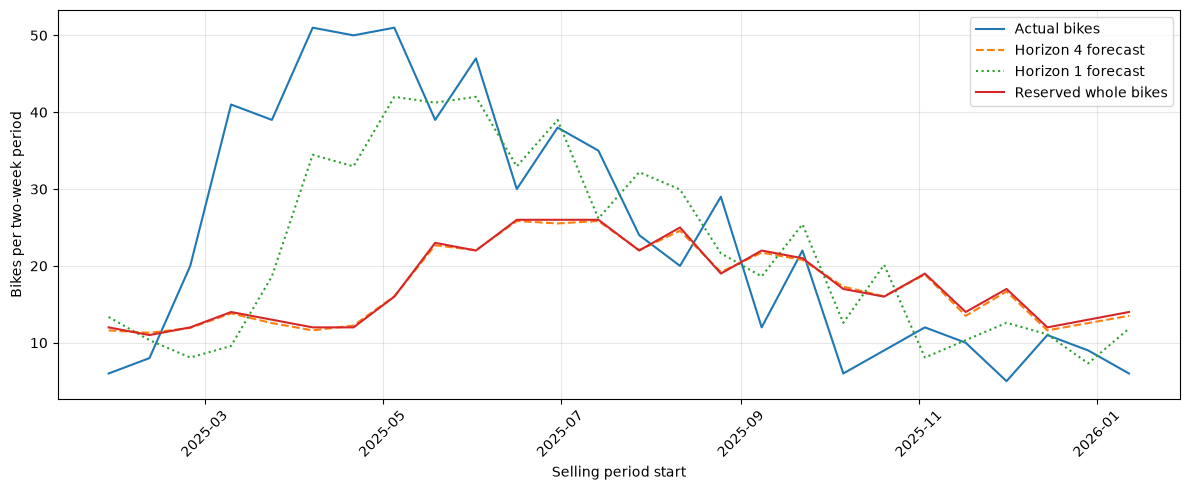

In [48]:
plt.figure(figsize=(12, 5))
plt.plot(df_results["period_start"], df_results["total_demand"], label="Actual bikes")
plt.plot(df_results["period_start"], df_results["forecast_h4"], "--", label="Horizon 4 forecast")
plt.plot(df_results["period_start"], df_results["forecast_h1"], ":", label="Horizon 1 forecast")
plt.plot(df_results["period_start"], df_results["capacity"], label="Reserved whole bikes")
plt.xlabel("Selling period start")
plt.ylabel("Bikes per two-week period")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/q3_demand_capacity.png", dpi=150)
plt.show()


### Prices and quantities over the test period

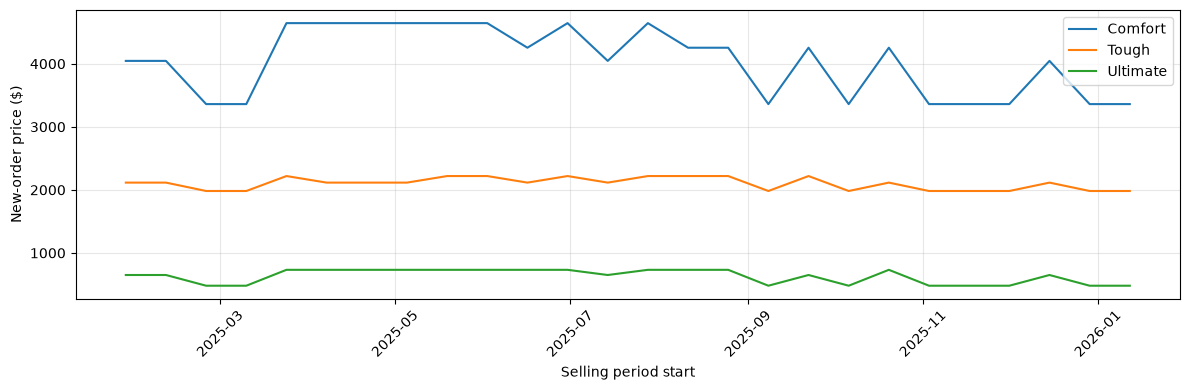

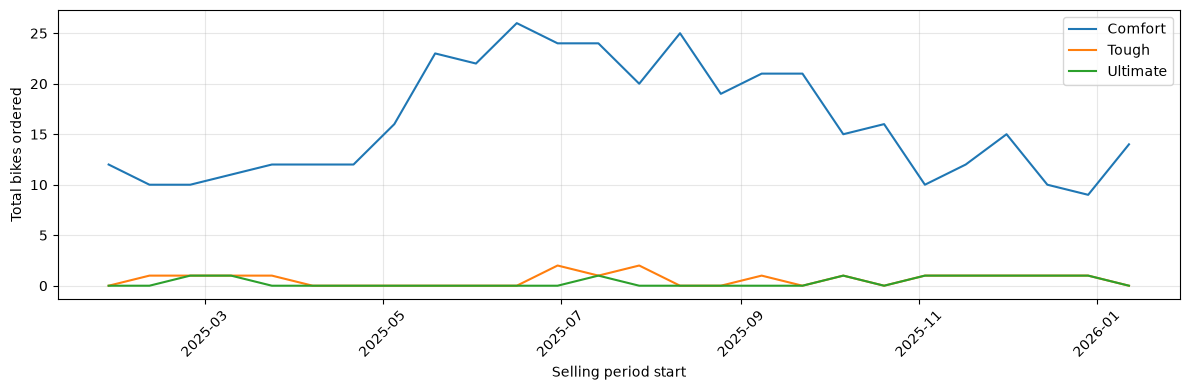

In [49]:
for measure in ["price", "quantity"]:
    plt.figure(figsize=(12, 4))
    plt.plot(df_results["period_start"], df_results[measure + "_comfort"], label="Comfort")
    plt.plot(df_results["period_start"], df_results[measure + "_tough"], label="Tough")
    plt.plot(df_results["period_start"], df_results[measure + "_ultimate"], label="Ultimate")
    plt.xlabel("Selling period start")
    plt.ylabel("New-order price ($)" if measure == "price" else "Total bikes ordered")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("outputs/q3_" + measure + ".png", dpi=150)
    plt.show()


### Sensitivity to missing no-purchase information

All 26 periods are recalculated for the nine conversion/response combinations. Every scenario preserves the same horizon-4 reservation and is calibrated to
the same reference purchase forecast. The central scenario is not chosen by selecting whichever assumption produces the largest modeled revenue.

In [50]:
sensitivity_rows = []
for conversion in [0.25, 0.50, 0.75]:
    for response in [1.0, 2.0, 3.0]:
        for i in range(len(df_test)):
            row = df_test.iloc[i]
            prices, extra, revenue = find_best_plan(
                row["remaining_forecast"], int(row["remaining_capacity"]), conversion, response
            )
            quantities = extra + np.array(row[booked_columns], dtype=int)
            sensitivity_rows.append([row["period_start"], conversion, response, row["capacity"]]
                                    + list(prices) + list(quantities) + [revenue + row["booked_revenue"]])
df_sensitivity = pd.DataFrame(sensitivity_rows, columns=[
    "period_start", "base_conversion", "price_sensitivity", "capacity",
    "price_comfort", "price_tough", "price_ultimate",
    "quantity_comfort", "quantity_tough", "quantity_ultimate", "modeled_revenue"
])
df_sensitivity.to_csv("outputs/q3_no_purchase_sensitivity.csv", index=False)
print("Scenario-period rows:", len(df_sensitivity))


Scenario-period rows: 234


### Ranges of decisions across the nine scenarios

In [51]:
df_sensitivity["ordered_total"] = df_sensitivity[quantity_columns].sum(axis=1)
df_robustness = df_sensitivity.groupby("period_start")[[
    "price_comfort", "price_tough", "price_ultimate", "ordered_total"
]].agg(["min", "max"])
print(df_robustness.to_string())
df_robustness.to_csv("outputs/q3_robustness.csv")
print("Updated plans differ from old-forecast plans:", df_comparison["plan_changed"].sum())


             price_comfort         price_tough         price_ultimate        ordered_total    
                       min     max         min     max            min    max           min max
period_start                                                                                  
2025-01-27          4045.0  4254.0      2115.0  2219.0          560.0  732.0            12  12
2025-02-10          3360.0  4254.0      1800.0  2219.0          480.0  732.0            11  11
2025-02-24          3360.0  4254.0      1800.0  2219.0          480.0  732.0            10  12
2025-03-10          3360.0  4254.0      1800.0  2219.0          480.0  732.0            11  14
2025-03-24          4254.0  4644.0      2115.0  2219.0          649.9  732.0            13  13
2025-04-07          4644.0  4882.0      2115.0  2219.0          732.0  732.0            12  12
2025-04-21          4644.0  4882.0      2115.0  2219.0          732.0  732.0            12  12
2025-05-05          4644.0  4882.0      2115.0  22

Comfort and Tough recommended prices vary across scenarios in 24 of the 26 periods. Ultimate prices vary in 21 periods. For January 27, 2025, Comfort prices range from \$4,045 - \$4,254, Tough prices from \$2,115 - \$2,219, and Ultimate prices from \$560 - \$732. Total orders remain 12 in that period. Capacity is unchanged in every scenario because it is determined by the early point forecast.

### Interpretation and limitations

The horizon-4 rule fixes capacity before more recent sales information becomes available. Later forecasts can change the price and product allocation within that reservation. The numerical optima are conditional on the revenue objective, price grid and participation scenario; they are not a unique profit-maximizing business solution.

The reference-basket calibration assumes that the OLS purchase forecast can be interpreted at training median prices. Potential traffic and average order sizes are held stable within each scenario. Demand is represented by point estimates, with no stockout substitution or inventory carryover. Applying minimum of quantity and point demand is not the same as evaluating expected sales under a full demand distribution. Historical price associations may also reflect
unobserved trading conditions rather than causal price effects.

The analysis is a conditional replay using observed history, not a simulation of how earlier recommended prices would have changed later observed sales and bookings. Modeled revenue is therefore not realized counterfactual revenue. Visitor counts, non-purchase observations, product costs and experimental price response data would strengthen the business recommendations.